# Machine Learning for Gold and Oil Return Forecasting: From Predictive Accuracy to Trading Performance

**Course:** Machine Learning for Portfolio Management and Trading, ENSAE Paris, 3A

**Authors:** DJIEMON YOUMBI Evan & HOUNKPE Patrick Junior |  **Date:** 13 November 2026

**Abstract.** We revisit Cohen & Aiche (2023), who forecast daily gold-price changes with tree-based models on a panel of global stock indices, commodities and bond yields. We rebuild the dataset from public sources up to January 2026, replace the single train/test split by a tuning period followed by a rolling walk-forward out-of-sample period (2021–2026), and convert each forecast into a position to evaluate the models' performance  on the market (PnL, Sharpe ratio, drawdown).

**Contents**
1. [Introduction](#1.-Introduction)
2. [Dataset overview](#2.-Dataset-overview)
3. [Analytics and learning strategies](#3.-Analytics-and-learning-strategies)
4. [Empirical results: baseline and robustness](#4.-Empirical-results:-baseline-and-robustness)
5. [Conclusion](#5.-Conclusion)
6. [References](#References)

In [1]:
%pip install pandas requests yfinance scikit-learn matplotlib joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from dataclasses import dataclass
import io
import math
from typing import Callable

from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import yfinance as yf

from sklearn.base import BaseEstimator, clone
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.metaestimators import _safe_split
from sklearn.tree import DecisionTreeRegressor

# 1. Introduction

## 1.1 Contextual background

Gold is widely regarded as a *hedge* against inflation and a *safe haven* during stock-market stress and economic uncertainty. Forecasting its price is therefore valuable for portfolio managers, hedgers and financial institutions who want to include gold in their portfolios (Cohen & Aiche, 2023).

Cohen & Aiche (2023) predict the daily change of the gold price with a regression tree, a random forest, gradient-boosted regression trees and XGBoost. Their predictors cover three markets : stocks (the 38 OECD stock indices), commodities (silver, oil, natural gas, wheat) and bonds (US, German, French, Japanese 10-year yields) and the VIX, with lags up to 10 days and moving averages. Their main finding is that one-day-lagged stock indices (ASX, S&P 500, TA35, IBEX, AEX), US and Japanese yields, lagged gas and silver, and the VIX carry predictive information, and that boosted trees give the lowest test error.

**Gaps and open questions.** In that paper:
- performance is measured with statistical losses (test MSE and relative MSE) and **not economically** : There is no strategy, no PnL, no Sharpe ratio;
- the evaluation relies on a **single** train/test split (26 September 2019) as stated in the paper.

*The questions we are tackling in this project:* Is the predictability of next-day gold returns **economically exploitable** once forecasts are turned into positions? Are the features used **specific to gold** or do they extend to another commodity (**oil, in our case**)? And can the predictions and therefore the economic performance be enhanced by adding data from hedge funds positions provided by the Commitment of Traders on the CFTC?

## 1.2 Project contributions

- **Data:** the dataset is rebuilt from public sources (Yahoo Finance via `yfinance`, FRED for the US 10-year yield) from 2000 to January 2026, with the code provided for full reproducibility.
- **Evaluation protocol:** hyper-parameters are tuned on data up to 2020-12-31 only; the period 2021–2026 is evaluated with a **rolling walk-forward** scheme.
- **From forecasts to a strategy:** each prediction is turned into a position with a volatility-scaled mean-variance timing rule which we got from the `skfin` Github repository. We hten report cumulative PnL, annualised Sharpe ratio and drawdown.
- **Algorithms and tuning:** Decision Tree, Random Forest and Gradient Boosting, tuned with randomised search and time-series cross-validation.
- **Feature selection and robustness:** two selection schemes (permutation importance of a random forest and persistence of LASSO selection across time-series folds) are used to do feature selection.
- **Extension:** the same pipeline is applied to **oil**, to check whether the gold result is asset-specific.
- **Hedge funds net positions** : (TO BE COMPLETED)

## 1.3 Summary of the main empirical results

- **Gold, baseline:** Gradient Boosting reaches a Sharpe ratio of **≈ 1.42**, Random Forest **≈ 0.78** and the Decision Tree **≈ 0.23**.
- **Robustness:** with reduced feature sets Gradient Boosting stays between **≈ 1.07 and 1.29** for gold, meaning that the main finding survives. On the other hand, the Random Forest and the Decision Tree are much less stable.
- **Oil:** the baseline strategies are not profitable (Sharpe between **−0.51 and −0.19**), and results after feature selection are inconsistent across models — the pattern is therefore **specific to gold**.


## 1.4 Literature and resources

**Academic references**
- Cohen, G. & Aiche, A. (2023). *Forecasting gold price using machine learning methodologies.* Chaos, Solitons & Fractals, 175, 114079. https://doi.org/10.1016/j.chaos.2023.114079.

**Software and data**
- `pandas`, `numpy`, `matplotlib`, `scikit-learn` (trees, forests, boosting, LASSO, `TimeSeriesSplit`, `RandomizedSearchCV`, `permutation_importance`), `joblib`.
- `yfinance` (Yahoo Finance prices) and FRED series `DGS10` (US 10-year Treasury yield).
- `Backtester`, `sharpe_ratio` and plotting helpers are adapted from https://github.com/schampon/skfin.

# 2. Dataset overview

## 2.1 Origin and composition of the data

**Variables used** (almost same universe as in the paper, plus oil)

The data that is used in the paper is related to various financial instruments:

- GOLD --> Gold futures
- Silver --> Silver futures
- Wheat -->	Wheat futures
- GAZ -->	Natural gas futures
- SP500 -->	S&P 500	
- NSDQ -->	Nasdaq Composite
- VIX -->	Volatility index
- IBEX -->	IBEX 35 (Spain)
- AEX -->	AEX (Netherlands)
- BEL -->	BEL 20 (Belgium)
- DAX -->	DAX (Germany)
- FTSE -->	FTSE 100 (UK)
- SMI -->	Swiss Market Index
- ASX -->	ASX 200 (Australia)
- N225 -->	Nikkei 225
- HIS -->	Hang Seng
- Nifty -->	Nifty 50 (India)
- BVSP -->	Bovespa (Brazil)	
- NZX -->	NZX 50 (New Zealand)
- US yield  -->	US 10-year Treasury

**Sources.** Daily closing prices from Yahoo Finance (`yfinance`) for commodity futures and equity indices, and the US 10-year Treasury yield from FRED (`DGS10`). Oil futures (`CL=F`) are added as an extension. Sample: **2000-01-01 → 2026-01-30**, daily frequency.

**Differences with the paper.** Only the US yield is used. 15 equity indices are used (instead of the 38 OECD indices). The sample extends to 2026. 

The dataset is **built from scratch by the code below**, so the study is fully reproducible.

In [3]:
START = "2000-01-01"
END = "2026-01-30" 
PERIOD = '1d'
RNDM_SEED = 42 # To ensure reproducibility
YAHOO = {
    "gold":   ["GC=F"],
    "silver": ["SI=F"],
    "wheat":  ["ZW=F"],
    "gaz":    ["NG=F"],
    "sp500":  ["^GSPC"],
    "nsdq":   ["^IXIC"],
    "vix":    ["^VIX"],
    "ibex":   ["^IBEX"],
    "aex":    ["^AEX"],
    "bel":    ["^BFX"],
    "dax":    ["^GDAXI"],
    "ftse":   ["^FTSE"],
    "smi":    ["^SSMI"],
    "asx":    ["^AXJO"],
    "n225":   ["^N225"],
    "his":    ["^HSI"],
    "nifty":  ["^NSEI"],
    "bvsp":   ["^BVSP"],
    "nzx":    ["^NZ50"],
    "ta35":   ["TA35.TA"],
    "oil": ["CL=F"]
}

**Data-collection and cleaning functions.**

In [4]:
def fetch_single_asset(name):
    ticker = YAHOO[name]

    try:
        data = yf.download(
            tickers=ticker,
            interval=PERIOD,
            start=START,
            end=END
        )

        close = data["Close"].iloc[:, 0]
        
        close.name = name
        return close

    except Exception as e:
        print(f"{name}: {e}")
        return None

def fetch_all():

    # Fetch Yahoo data
    dico = {}

    for name in YAHOO.keys():
        result = fetch_single_asset(name)

        if result is not None:
            dico[name] = result

    yahoo_df = pd.concat(dico, axis=1, sort=True)

    # Fetch US yield data
    url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS10"
    r = requests.get(url, timeout=30)
    r.raise_for_status()

    df = pd.read_csv(
        io.StringIO(r.text),
        index_col=0,
        parse_dates=True
    )

    usyield = pd.to_numeric(df.iloc[:, 0], errors="coerce").loc[START:END]
    usyield.name = "us_yield"

    # Combine all data
    data = pd.concat(
        [yahoo_df, usyield],
        axis=1,
        sort=True
    )

    return data

def check_data_validity(data: pd.DataFrame, verbose: bool = True) -> pd.DataFrame:

    # Check the validity of the timestamps
    if not isinstance(data.index, pd.DatetimeIndex):
        data.index = pd.to_datetime(data.index, errors="raise")

    # Check the ordering of observations
    if not data.index.is_monotonic_increasing:
        data.sort_index(ascending=True, inplace=True)

    # Check for missing values
    missing_cols = data.columns[data.isna().any()]

    if len(missing_cols) > 0:
        data.loc[:, missing_cols] = data.loc[:, missing_cols].ffill()

    return data.dropna()

In [5]:
allData = fetch_all()
cleaned_data = check_data_validity(allData, verbose=False)

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%********

## 2.2 Chronological accuracy of the data (no look-ahead)

Markets close at different times and on different holidays, so the series are aligned on a common calendar and **forward-filled** (`ffill`) where a market is closed. This only uses past information. The side-effect is that forward-filling creates artificial zero returns on holidays.

To make sure that every date reflects information that was actually available:
- all series are transformed into **returns** (`pct_change`) and every feature is a **lag** (`shift(i)`, `i ≥ 1`) or a moving average of **lagged** returns (`shift(1).rolling(...)`), so a feature dated *t* only uses information up to *t*;
- the target is the return of **day *t+1***, predicted from features dated *t*;
- in the backtest, the position computed at *t* is applied to the return of *t+1* (`pred_lag = 1`);
- hyper-parameters and selected features use data up to **2020-12-31 only**, so the 2021–2026 evaluation period is never seen during tuning.

## 2.3 Descriptive statistics
We look at:
- the distribution of daily returns
- the contemporaneous correlation of each asset with gold.

,mean (*10^4) (%),volatility (%)
gold,4.80,17.57
oil,-4.73,86.77
silver,6.71,32.75
sp500,4.00,19.65
vix,28.70,127.23


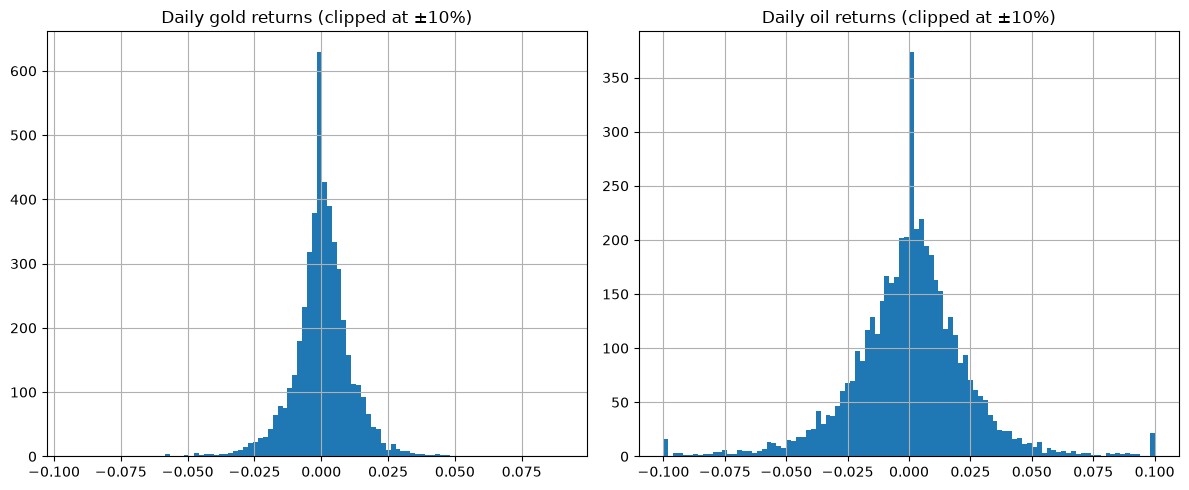

In [ ]:
rets = cleaned_data.pct_change(fill_method=None).dropna()

stats = pd.DataFrame({
    "mean (*10^4) (%)": rets.mean() * 1e4,
    "volatility (%)": rets.std() * np.sqrt(252) * 100,
}).round(2)

display(stats.loc[["gold", "oil", "silver", "sp500", "vix"]])


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, a in zip(axes, ["gold", "oil"]):
    rets[a].clip(-0.1, 0.1).hist(bins=100, ax=ax)
    ax.set_title(f"Daily {a} returns (clipped at ±10%)")

plt.tight_layout()
plt.show()

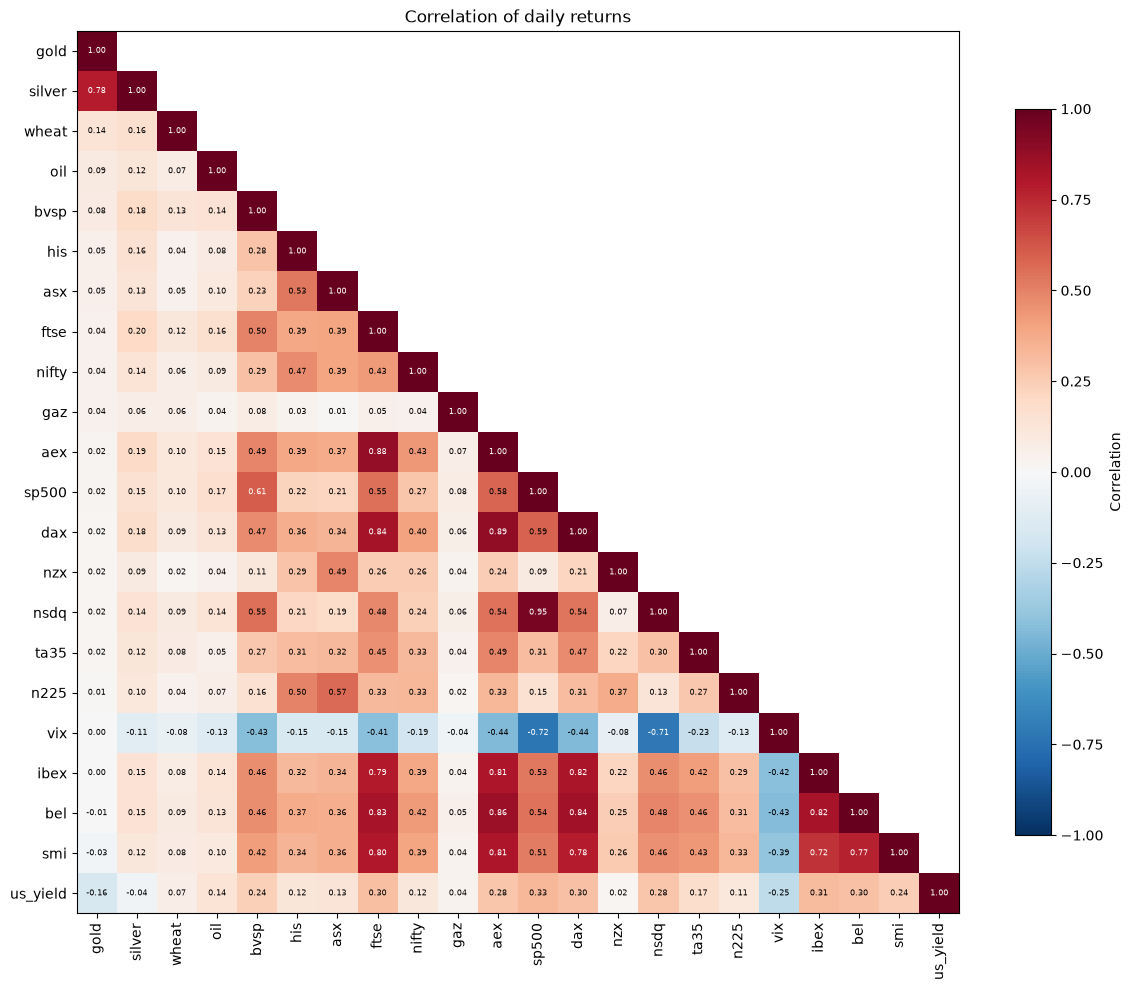

In [ ]:
# This part was written by Claude
corr = rets.corr()

order = corr["gold"].sort_values(ascending=False).index
corr = corr.loc[order, order]

mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
data = np.ma.masked_where(mask, corr.values)

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(data, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index)

for i in range(len(corr)):
    for j in range(i + 1):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")

fig.colorbar(im, ax=ax, shrink=0.8, label="Correlation")
ax.set_title("Correlation of daily returns")

plt.tight_layout()
plt.show()

From these results we can see that on the period we're studying, gold is much less volatile than oil and equities. This could hint towards the fact that algorithms could predict gold returns better than the other assets we're considering.

Also, there is low correlation between gold returns and other assets whereas there is a higher correlation with silver returns. This was to be anticipated because silver prices and gold prices are known to be correlated.

Oil, on the other hand, also doesn't have a high correlation with the other assets.

In [8]:
# VIX regime used in the paper: dummy = 1 if VIX > 20
print("Share of days with VIX > 20:", round((cleaned_data["vix"] > 20).mean(), 3)*100,"%")

Share of days with VIX > 20: 36.5 %


Cohen & Aiche consider that when VIX > 20, this means there is panic on the market. According to their study, this feature was important to predict gold returns. Having 36.5% of days considered as panic days is good because this would mean that considering this variable is important and allow to discriminate and partition our space of features. 

# 3. Analytics and learning strategies

## 3.1 Features and target

For each asset, daily **returns** are computed, then **lags 1 to 10** of every asset (including the target asset itself) are created, together with **moving averages (orders 2 to 10) of the lagged target returns** and the **VIX dummy** (VIX > 20), as in Cohen & Aiche (2023). The target is the next-day return of gold (or oil).

In [9]:
def build_features(data: pd.DataFrame, lag_order: int = 10, target_col: str = "oil") -> tuple[pd.DataFrame]:

    data = data.copy()

    return_cols = data.columns.tolist()
    predictions_cols = []

    # transform the VIX in a dummy variable
    data["vix_dummy"] = (data["vix"] > 20).astype("int8")
    predictions_cols.append("vix_dummy")

    # transform every columns into returns
    # I did a forward:backward fill so when computing returns, there will be articial zeros in the dataset. We should think about it
    
    data[return_cols] = data[return_cols].pct_change(fill_method=None)

    # compute lag up to order 10 of all the columns
    lag_features = {
        f"{col}_lag_{i}": data[col].shift(i)
        for col in return_cols
        for i in range(1, lag_order+1)
    }
    predictions_cols.extend(lag_features.keys())
    data = pd.concat([data, pd.DataFrame(lag_features, index=data.index)], axis=1)

    # moving_averages on the target_col up order 10. we exclude order 1 since it is equivalent to just seeing lag 1. It would introduce a duplicate column
    ma_features = {
        f"{target_col}_ma{i}": data[target_col].shift(1).rolling(window=i, min_periods=i).mean()
        for i in range(2, lag_order + 1)
    } 
    predictions_cols.extend(ma_features.keys())
    data = pd.concat([data, pd.DataFrame(ma_features, index=data.index)],axis=1)

    prediction_dataset = data[predictions_cols+[target_col]].dropna()
    target = prediction_dataset[target_col]
    features =  prediction_dataset[predictions_cols]

    # Verifications
    assert (np.all(features.index == target.index))
    assert(len(features.index) == features.index.nunique())
    assert(features.isna().any().sum() == 0)
    assert(target.isna().any().sum() == 0)
    assert(np.isfinite(features).all().all() and np.isfinite(target).all().all())
    
    return features, target, data[return_cols]

In [10]:
features_oil, target_oil, _ = build_features(cleaned_data, lag_order=10, target_col="oil")
features_gold, target_gold, _ = build_features(cleaned_data, lag_order=10, target_col="gold")

## 3.2 Algorithms

**Decision tree (regression tree).** Recursively splits the feature space into regions and predicts the mean target in each leaf, minimising the sum of squared errors $\sum_{c}\sum_{i\in c}(y_i-m_c)^2$. Easy to interpret, but high variance.

**Random forest.** Averages $B$ trees, each grown on a bootstrap sample with a random subset of features at each split: $\hat f(x)=\frac1B\sum_{b=1}^B T_b(x)$. Averaging decorrelated trees lowers variance.

**Gradient boosting.** Builds trees sequentially, each fitted to the negative gradient (the residuals, for squared loss) of the current ensemble: $f_m(x)=f_{m-1}(x)+\nu\, T_m(x)$ with learning rate $\nu$. Shallow trees plus a small learning rate act as regularisation.

**Feature selection.** 

(i) *Permutation importance* of the random forest, averaged over time-series folds, keeping the top 50 features; 

(ii) *LASSO persistence*: a `LassoCV` is fitted on each time-series fold and features are ranked by how often their coefficient is non-zero.

## 3.3 Data partitioning: training, validation and test

| Period | Use |
|---|---|
| start → **2020-12-31** | **Tuning set.** Hyper-parameter search and feature selection, with time-series cross-validation  |
| **2021-01-01** → 2026-01-30 | **Out-of-sample test.** Walk-forward. Nothing from this period is used for tuning. |

No shuffling is used anywhere, and every validation window lies strictly after its training window.

In [11]:
def prepare_tuning_data(features: pd.DataFrame, target: pd.DataFrame, tuning_end_date: str = "2020-01-01"):

    x = features
    y = target

    data = x.join(y.rename("target"), how="inner").sort_index()
    data = data.replace([np.inf, -np.inf], np.nan).dropna()

    x = data.drop(columns="target")
    y = data["target"]
    y_next = y.shift(-1).rename("target_next").dropna() # Features at t predict the return at t+1

    supervised_data = x.join(y_next).dropna()

    tuning_end = tuning_end_date 
    tuning_data = supervised_data.loc[:tuning_end]

    X_tune = tuning_data[x.columns]
    y_tune = tuning_data["target_next"]

    return X_tune, y_tune

## 3.4 Parameter selection and optimisation

Hyper-parameters are chosen by **randomised search** over the grids below, with `TimeSeriesSplit` cross-validation and **RMSE** as the criterion. The best configuration of each model is then re-used, unchanged, in the walk-forward backtest.

In [12]:
models_and_params = {
    "Decision Tree": (
        DecisionTreeRegressor(random_state=RNDM_SEED),
        {
            "max_depth": [2, 3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Random Forest": (
        RandomForestRegressor(random_state=RNDM_SEED, n_jobs=1),
        {
            "max_depth": [3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30],
            "max_features": [1.0, 0.5, "sqrt"],
        },
    ),
    "Gradient Boosting": (
        GradientBoostingRegressor(random_state=RNDM_SEED),
        {
            "n_estimators": [50, 100, 200, 300],
            "learning_rate": [0.01, 0.03, 0.05, 0.1],
            "max_depth": [1, 2, 3, 5, 8],
            "min_samples_leaf": [5, 10, 20, 30]
        },
    ),
}

TUNING_END_DATE = "2020-12-31"
PREDICTION_START_DATE = "2021-01-01"

X_tune_oil, y_tune_oil = prepare_tuning_data(features=features_oil, target=target_oil, tuning_end_date=TUNING_END_DATE)
X_tune_gold, y_tune_gold = prepare_tuning_data(features=features_gold, target=target_gold, tuning_end_date=TUNING_END_DATE)

In [13]:
def hyperparameter_optimization(features: pd.DataFrame, 
                                target: pd.Series | pd.DataFrame, 
                                models_and_params: dict, 
                                n_splits: int = 5,
                                max_train_size: int = 60,
                                test_size: int = 30):
    
    cv = TimeSeriesSplit(
        n_splits=n_splits,
        max_train_size=max_train_size,
        test_size=test_size,
    )

    best_models = {}

    for name, (model, param_grid) in models_and_params.items():
        search = RandomizedSearchCV(
            estimator=model,
            param_distributions=param_grid,
            n_iter=25,
            scoring="neg_root_mean_squared_error",
            cv=cv,
            random_state=RNDM_SEED,
            n_jobs=-1,
            refit=True,
            error_score="raise",
        )

        search.fit(features, target)

        best_models[name] = search.best_estimator_

        print(f"\n{name}")
        print("Best parameters:", search.best_params_)
        print("CV RMSE:", round(-search.best_score_, 6))

    return best_models

In [14]:
best_models_oil = hyperparameter_optimization(features=X_tune_oil, target=y_tune_oil, models_and_params=models_and_params)
best_models_gold = hyperparameter_optimization(features=X_tune_gold, target=y_tune_gold, models_and_params=models_and_params)


Decision Tree
Best parameters: {'min_samples_leaf': 30, 'max_features': 0.5, 'max_depth': 8}
CV RMSE: 0.039646

Random Forest
Best parameters: {'min_samples_leaf': 30, 'max_features': 'sqrt', 'max_depth': 8}
CV RMSE: 0.030555

Gradient Boosting
Best parameters: {'n_estimators': 50, 'min_samples_leaf': 30, 'max_depth': 8, 'learning_rate': 0.01}
CV RMSE: 0.030866

Decision Tree
Best parameters: {'min_samples_leaf': 30, 'max_features': 0.5, 'max_depth': 8}
CV RMSE: 0.011352

Random Forest
Best parameters: {'min_samples_leaf': 20, 'max_features': 1.0, 'max_depth': 8}
CV RMSE: 0.010724

Gradient Boosting
Best parameters: {'n_estimators': 50, 'min_samples_leaf': 30, 'max_depth': 8, 'learning_rate': 0.01}
CV RMSE: 0.010772


## 3.5 Implementation of the backtest and performance metrics

In [15]:
"""Backtest class and methods to compute predictions and holdings in portfolio"""

def compute_pnl(
    h: pd.DataFrame | pd.Series,
    ret: pd.DataFrame | pd.Series,
    pred_lag: int = 1,
) -> pd.Series:
    """Compute PnL from holdings and returns.

    Args:
        h: Holdings at each time step.
        ret: Asset returns.
        pred_lag: Number of periods to lag holdings (avoids lookahead).

    Returns:
        PnL series (summed across assets if multi-asset).
    """
    pnl = h.shift(pred_lag).mul(ret)
    if isinstance(h, pd.DataFrame):
        pnl = pnl.sum(axis=1)
    return pnl

def fit_predict(
    estimator: BaseEstimator,
    X: np.ndarray,
    y: np.ndarray,
    train: np.ndarray,
    test: np.ndarray,
    return_estimator: bool = True,
) -> tuple:
    """Fit estimator on train split and predict on test split.

    Args:
        estimator: sklearn-compatible estimator.
        X: Feature matrix.
        y: Target matrix.
        train: Train indices.
        test: Test indices.
        return_estimator: If True, return (predictions, fitted_estimator).

    Returns:
        Predictions, or tuple of (predictions, estimator).
    """
    X_train, y_train = _safe_split(estimator, X, y, train)
    X_test, _ = _safe_split(estimator, X, y, test, train)
    estimator.fit(X_train, y_train)
    if return_estimator:
        return estimator.predict(X_test), estimator
    else:
        return estimator.predict(X_test)

@dataclass
class Backtester:
    """Walk-forward backtester for prediction and portfolio timing."""

    estimator: BaseEstimator | None = None
    max_train_size: int = 36
    test_size: int = 1
    pred_lag: int = 1
    start_date: str = "2022-01-01"
    end_date: str | None = None
    name: str | None = None

    def __post_init__(self):
        if self.estimator is None:
            from sklearn.tree import DecisionTreeRegressor
            self.estimator = DecisionTreeRegressor(
                max_depth=5,
                min_samples_leaf=10,
                random_state=RNDM_SEED,
            )

    def compute_predictions(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
        n_jobs: int = 1,
    ):
        """Generate out-of-sample predictions with walk-forward validation."""

        common_idx = X.index.intersection(y.index).sort_values()
        X = X.loc[common_idx].sort_index()
        real = y.copy() # temp data to store y
        y = y.loc[X.index].shift(-1).dropna()

        if self.end_date is not None:
            mask = X.index <= pd.Timestamp(self.end_date)
            X, y = X.loc[mask], y.loc[mask]

        n_test = len(X.loc[self.start_date:])
        if n_test == 0:
            raise ValueError("No observations found on or after start_date.")

        n_splits = math.ceil(n_test / self.test_size)
        if n_splits >= len(X):
            raise ValueError("Not enough observations for walk-forward training.")

        cv = TimeSeriesSplit(
            max_train_size=self.max_train_size,
            test_size=self.test_size,
            n_splits=n_splits,
        )

        def fit_predict(train, test):
            model = clone(self.estimator)
            model.fit(X.iloc[train], y.iloc[train])
            return model.predict(X.iloc[test]), model, test

        results = Parallel(n_jobs=n_jobs)(
            delayed(fit_predict)(train, test)
            for train, test in cv.split(X)
        )

        predictions = np.concatenate([r[0] for r in results], axis=0)
        test_indices = np.concatenate([r[2] for r in results])
        pred_idx = X.index[test_indices]

        mask = pred_idx >= pd.Timestamp(self.start_date)
        if self.end_date is not None:
            mask &= pred_idx <= pd.Timestamp(self.end_date)

        predictions = predictions[mask]
        pred_idx = pred_idx[mask]

        if isinstance(y, pd.DataFrame):
            self.predictions_ = pd.DataFrame(
                predictions, index=pred_idx, columns=y.columns
            )
        else:
            self.predictions_ = pd.Series(
                np.asarray(predictions).reshape(-1),
                index=pred_idx,
                name=self.name or "prediction",
            )

        self.actual_ = real.loc[pred_idx]
        self.estimators_ = tuple(r[1] for r in results)
        self.cv_ = cv

        return self

    def compute_holdings(
        self,
        X: pd.DataFrame,
        y: pd.Series | pd.DataFrame,
        n_jobs: int = 1,
    ):
        """Generate out-of-sample portfolio holdings."""
        self.compute_predictions(X, y, n_jobs=n_jobs)

        tmv = TimingMeanVariance(a_min=-0.25, a_max=0.25)
        tmv.fit(None, self.predictions_)
        self.h_ = pd.Series(
            tmv.predict(self.predictions_),
            index=self.predictions_.index
        )

    def compute_pnl(self, ret: pd.DataFrame | pd.Series):
        """Compute PnL from fitted holdings and returns.

        Args:
            ret: Asset returns (same index/columns as y).

        Returns:
            self (with pnl_ fitted attribute).
        """
        pnl = compute_pnl(self.h_, ret, self.pred_lag)
        self.pnl_ = pnl.loc[self.start_date:self.end_date]
        if self.name:
            self.pnl_ = self.pnl_.rename(self.name)
        return self


def plot_result(predictions, actual, asset="Oil"):
    
    plt.figure(figsize=(8, 8))

    plt.scatter(predictions, actual, alpha=0.6)

    # Perfect prediction reference line
    limits = [
        min(np.min(predictions), np.min(actual)),
        max(np.max(predictions), np.max(actual))
    ]
    plt.plot(limits, limits, "r--", label="Perfect predictions")

    plt.xlabel(f"Predicted {asset} returns")
    plt.ylabel(f"Real {asset} returns")
    plt.title(f"Real vs Predicted {asset} Returns")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.axis("equal")
    plt.tight_layout()
    plt.show()

class TimingMeanVariance(BaseEstimator):
    """Single-asset timing estimator that scales positions by inverse volatility."""

    def __init__(
        self,
        transform_V: Callable | None = None,
        a_min: float | None = None,
        a_max: float | None = None,
    ):
        if transform_V is None:
            self.transform_V = lambda x: np.var(x)
        else:
            self.transform_V = transform_V
        self.a_min = a_min
        self.a_max = a_max

    def fit(self, X, y=None):
        self.V_ = self.transform_V(y)
        return self

    def predict(self, X):
        if self.a_min is None and self.a_max is None:
            h = X / self.V_
        else:
            h = np.clip(
                X / np.sqrt(self.V_), a_min=self.a_min, a_max=self.a_max
            ) / np.sqrt(self.V_)
        return h

    def transform(self, X):
        """Alias for predict (enables sklearn pipeline use)."""
        return self.predict(X)

In [16]:
"""Performance and risk metrics."""

def _test_monthly(df: pd.Series) -> bool:
    """Check if the series has monthly frequency."""
    return int(len(df) / len(df.asfreq("ME"))) == 1

def _test_bday(df: pd.Series) -> bool:
    """Check if the series has business-day frequency."""
    return int(len(df) / len(df.asfreq("B"))) == 1

def _test_day(df: pd.Series) -> bool:
    """Check if the series has calendar-day frequency."""
    return int(len(df) / len(df.asfreq("D"))) == 1

def sharpe_ratio(
    df: pd.Series,
    num_period_per_year: int | None = None,
    remove_zeros: bool = True,
) -> float:
    """Compute annualized Sharpe ratio.

    Args:
        df: PnL or returns series with a DatetimeIndex.
        num_period_per_year: Annualization factor. Auto-detected from index if None.
        remove_zeros: Replace zeros with NaN before computing (avoids deflating vol).

    Returns:
        Annualized Sharpe ratio, or NaN if frequency cannot be detected.
    """
    if num_period_per_year is None:
        if _test_monthly(df):
            num_period_per_year = 12
        if _test_bday(df):
            num_period_per_year = 260
        if _test_day(df):
            num_period_per_year = 365
        if num_period_per_year is None:
            return np.nan
    if remove_zeros:
        df = df.replace(0, np.nan)
    return df.mean() / df.std() * np.sqrt(num_period_per_year)

def drawdown(
    x: pd.Series,
    return_in_risk_unit: bool = True,
    window: int = 36,
    num_period_per_year: int = 252,
) -> pd.Series:
    
    """Compute drawdown from peak cumulative PnL.

    Args:
        x: PnL or returns series.
        return_in_risk_unit: Normalize by rolling volatility for cross-strategy comparison.
        window: Rolling window for volatility estimate (in periods).
        num_period_per_year: Annualization factor for the volatility normalization.

    Returns:
        Drawdown series (non-positive values; 0 at peaks).
    """
    dd = x.cumsum().sub(x.cumsum().cummax())
    if return_in_risk_unit:
        return dd.div(x.rolling(window).std().mul(np.sqrt(num_period_per_year)))
    return dd

In [17]:
"""Visualization helpers for quick data exploration."""

def set_axis(
    ax: plt.Axes | None = None,
    figsize: tuple = (8, 5),
    title: str | None = None,
    fig: plt.Figure | None = None,
) -> tuple[plt.Figure, plt.Axes]:
    """Create or reuse a matplotlib figure and axes pair.

    Args:
        ax: Existing axes to reuse. If None, creates a new figure.
        figsize: Figure size as (width, height) in inches.
        title: Optional title for the axes.
        fig: Existing figure to associate with the axes.

    Returns:
        Tuple of (figure, axes).
    """
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=figsize)
    else:
        fig = fig or ax.get_figure()
    if title is not None:
        ax.set_title(title)
    return fig, ax

def line(
    df: pd.DataFrame | pd.Series | dict | list,
    sort: bool = True,
    figsize: tuple = (8, 5),
    ax: plt.Axes | None = None,
    title: str = "",
    cumsum: bool = False,
    loc: str = "center left",
    bbox_to_anchor: tuple | None = (1, 0.5),
    legend_sharpe_ratio: bool | None = None,
    legend: bool = True,
    yscale: str | None = None,
    start_date: str | None = None,
    num_period_per_year: int = 252
):
    """Plot one or more time series as lines.

    Args:
        df: Data to plot. Accepts DataFrame, Series, dict, or list of Series.
        sort: Sort columns by final value (highest on top).
        figsize: Figure size as (width, height) in inches.
        ax: Existing axes to plot on.
        title: Plot title.
        cumsum: Cumulate the series before plotting.
        loc: Legend location string.
        bbox_to_anchor: Legend anchor point.
        legend_sharpe_ratio: Append Sharpe ratio to legend labels. Auto-enabled with cumsum.
        legend: Whether to show the legend.
        yscale: Y-axis scale (e.g. "log").
        start_date: Trim data before this date.
    """
    df = df.copy() if isinstance(df, (pd.DataFrame, pd.Series)) else df
    if loc == "best":
        bbox_to_anchor = None
    if isinstance(df, (dict, list)):
        df = pd.concat(df, axis=1)
    if isinstance(df, pd.Series):
        df = df.to_frame()
    if start_date is not None:
        df = df[start_date:]
    if cumsum and legend_sharpe_ratio is None:
        legend_sharpe_ratio = True
    if legend_sharpe_ratio:
        df.columns = [f"{c}: sr={sharpe_ratio(df[c], num_period_per_year=num_period_per_year): 3.2f}" for c in df.columns]
    if cumsum:
        df = df.cumsum()
    if sort:
        df = df.loc[:, lambda x: x.iloc[-1].sort_values(ascending=False).index]
    if ax is None:
        fig, ax = set_axis(ax=ax, figsize=figsize)
    ax.set_axisbelow(True)
    ax.grid(True, linestyle="--", alpha=0.5)
    if title != "":
        ax.set_title(title)
    ax.plot(df.index, df.values)
    if legend:
        ax.legend(df.columns, loc=loc, bbox_to_anchor=bbox_to_anchor)
    if yscale == "log":
        ax.set_yscale("log")

def display_results(features: pd.DataFrame, target: pd.DataFrame, 
                    best_models: dict, start_date: str = "2019-01-01", asset="Oil", 
                    show_metrics: bool = False):

    results = {}
    prediction_metrics = {}
    pnl_series = {}
    drawdown_series = {}
    
    X = features
    y = target
    y_next = y.shift(-1).rename("target_next").dropna()

    for name, best_model in best_models.items():

        bt = Backtester(
            estimator=clone(best_model),
            max_train_size=120,
            test_size=40,
            pred_lag=1,
            start_date=start_date,
            name=name,
        )

        bt.compute_predictions(X, y)

        pred = bt.predictions_
        actual = y_next.reindex(pred.index)
        valid = actual.notna()
        pred, actual = pred[valid], actual[valid]

        prediction_metrics[name] = {
            "RMSE": mean_squared_error(actual, pred) ** 0.5,
            "MAE": mean_absolute_error(actual, pred),
            "R2": r2_score(actual, pred) if len(actual) > 1 else np.nan,
        }

        bt.compute_holdings(X, y)
        bt.compute_pnl(y)

        pnl = bt.pnl_.dropna()
        pnl_series[name] = pnl
        
        dd = drawdown(pnl,return_in_risk_unit=True)
        drawdown_series[name] = dd

        results[name] = {
            "Cumulated lnl": pnl.sum(),
            "Sharpe ratio": sharpe_ratio(pnl,num_period_per_year=252),
            "Max drawdown": dd.min(),
        }

    pnl = pd.DataFrame(pnl_series)
    dd = pd.DataFrame(drawdown_series)

    line(pnl,cumsum=True,title=f"Cumulated PnL for {asset}",start_date=start_date,loc="best")
    line(dd,cumsum=False,title=f"Drawdown for {asset}",start_date=start_date,legend_sharpe_ratio=False,loc="best")

    if show_metrics:

        prediction_table = pd.DataFrame(prediction_metrics).T
        performance_table = pd.DataFrame(results).T

        print("Out of sample Performance")
        display(prediction_table.round(4))

        print("Financial performance")
        display(performance_table.round(4))

**Feature-selection funstions**

In [18]:
def features_selector_rf(model, X_tune: pd.DataFrame, y_tune: pd.DataFrame, n_features: int = 50, show_features: bool = False):

    cv = TimeSeriesSplit(n_splits=5)
    fold_importances = []

    for train_idx, val_idx in cv.split(X_tune):
        selector = model
        selector.fit(X_tune.iloc[train_idx], y_tune.iloc[train_idx])

        importance = permutation_importance(
            selector,
            X_tune.iloc[val_idx],
            y_tune.iloc[val_idx],
            scoring="neg_root_mean_squared_error",
            n_repeats=5,
            random_state=RNDM_SEED,
            n_jobs=-1,
        )

        fold_importances.append(
            pd.Series(importance.importances_mean, index=X_tune.columns)
        )

    importance_scores = (
        pd.concat(fold_importances, axis=1)
        .mean(axis=1)
        .sort_values(ascending=False)
    )

    if show_features:
        display(importance_scores.head(n_features).to_frame("Importance"))

    return importance_scores.head(n_features).index.to_list()

In [19]:
def features_selector_lasso(
    X_tune: pd.DataFrame,
    y_tune: pd.Series,
    show_features: bool = False,
    selection_threshold: float = 0.0
):
    cv = TimeSeriesSplit(n_splits=5)
    selection_counts = pd.Series(0, index=X_tune.columns, dtype=int)

    for train_idx, _ in cv.split(X_tune):
        X_train = X_tune.iloc[train_idx]
        y_train = y_tune.iloc[train_idx]

        selector = make_pipeline(
            StandardScaler(),
            LassoCV(cv=5, max_iter=20_000, random_state=RNDM_SEED),
        )

        selector.fit(X_train, y_train)

        coefficients = selector.named_steps["lassocv"].coef_
        selected = np.abs(coefficients) > selection_threshold

        selection_counts.loc[X_tune.columns[selected]] += 1

    persistence = (selection_counts / cv.n_splits).sort_values(ascending=False)

    if show_features:
        display(
            persistence.head(50)
            .rename("Selection frequency")
            .to_frame()
        )

    return persistence[persistence>0].index.to_list()

# 4. Empirical results: baseline and robustness

## 4.1 Baseline results

**Baseline specification:** all 230 engineered features (22 series × 10 lags, 9 moving averages, 1 VIX dummy), hyper-parameters tuned up to 2020, walk-forward evaluation from 2021-01-01.

### 4.1.1 Gold

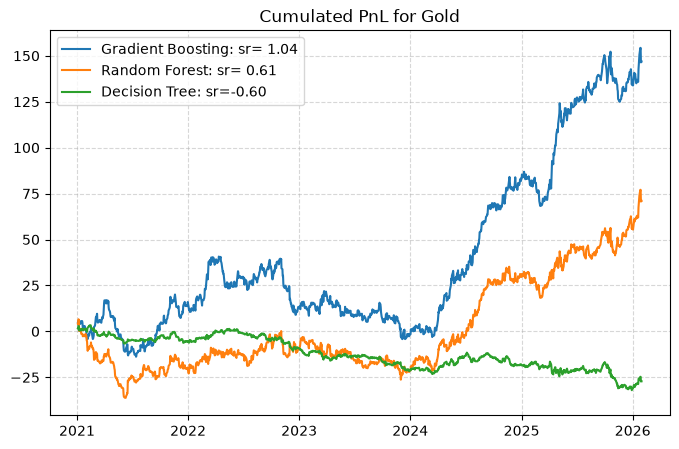

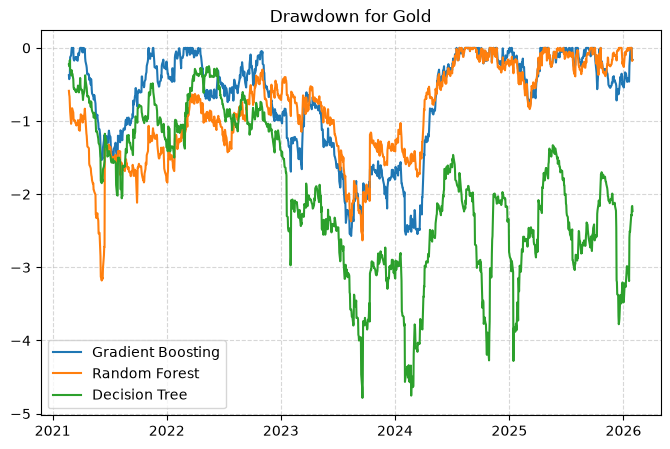

In [20]:
display_results(features=features_gold, target=target_gold, best_models=best_models_gold, start_date=PREDICTION_START_DATE, asset="Gold")

Gradient Boosting delivers the best risk-adjusted performance (**Sharpe = 1.04**), followed by Random Forest (= 0.61) and the Decision Tree is close to (= -0.60). The ranking *boosting > forest > tree* is the same as the accuracy ranking in Cohen & Aiche (2023), but here it is observed on an economic criterion and out of sample.

The cumulative PnL is modest and choppy until the end of 2024 and rises sharply from 2024 onwards, which coincides with the strong gold rally.So a large part of the performance comes from the **last two years**.

### 4.1.2 Extension: oil

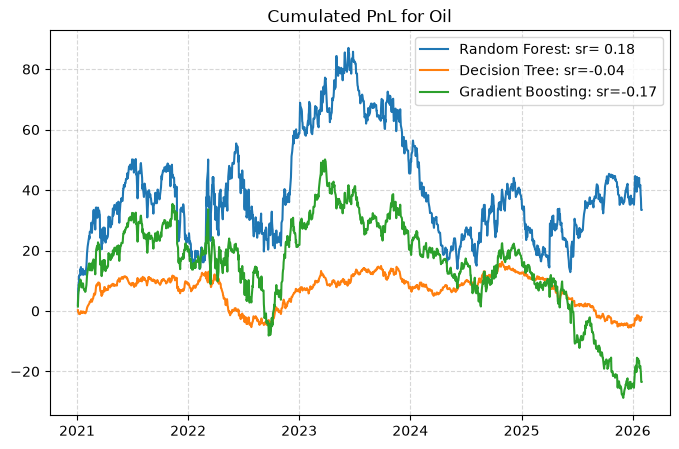

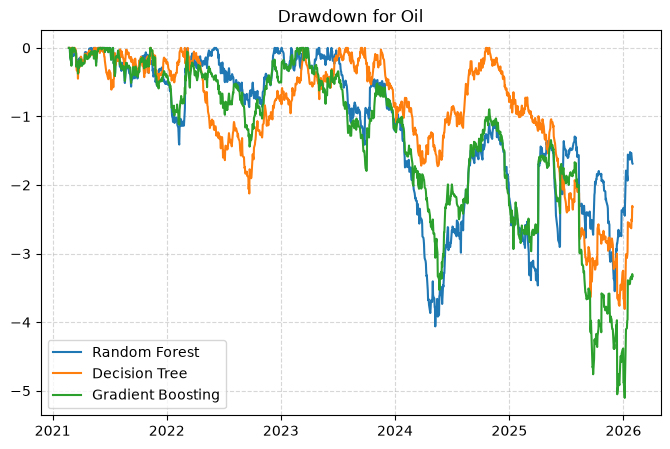

In [21]:
display_results(features=features_oil, target=target_oil, best_models=best_models_oil, start_date=PREDICTION_START_DATE)

Two of the three models are not profitable out of sample (Sharpe **≈ −0.04** for the tree, **−0.17** for boosting and **0.18** for the forest). The same pipeline that works for gold therefore **does not transfer to oil**, which suggests that the predictability found for gold is asset-specific. Random Forest is profitable but not at the same scale as it was for Gold.

## 4.2 Robustness tests

We test whether the main finding (boosted trees predict gold profitably) survives **algorithmic modifications**: a smaller feature set chosen by two different selection methods, and then a different training-window length.

### 4.2.1 Feature selection by random-forest permutation importance (top 25)

In [22]:
selected_features_oil_rf = features_selector_rf(model=best_models_oil["Random Forest"], X_tune=X_tune_oil, y_tune=y_tune_oil, n_features=25)
selected_features_gold_rf = features_selector_rf(model=best_models_gold["Random Forest"], X_tune=X_tune_gold, y_tune=y_tune_gold, n_features=25)

In [23]:
reduced_features_oil_rf = features_oil[selected_features_oil_rf]
reduced_features_gold_rf = features_gold[selected_features_gold_rf]

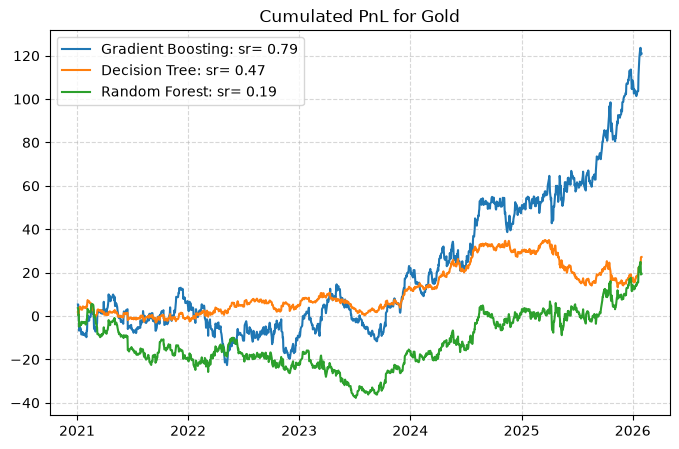

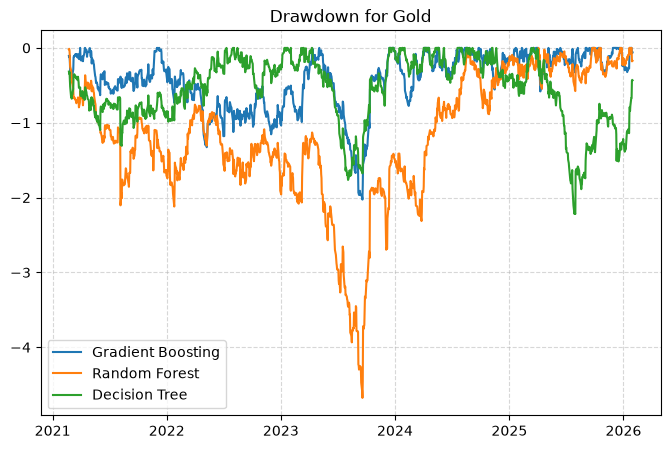

In [24]:
display_results(features=reduced_features_gold_rf, target=target_gold, best_models=best_models_gold, start_date=PREDICTION_START_DATE, asset="Gold")

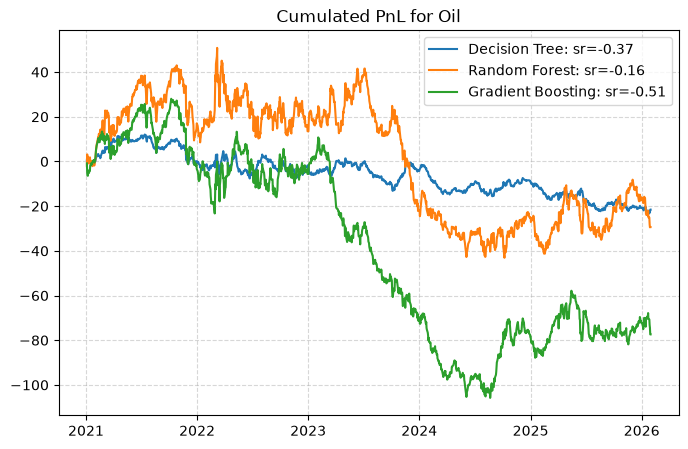

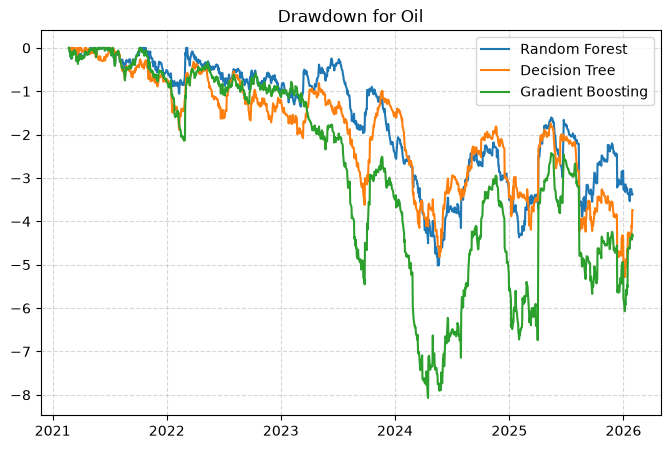

In [25]:
display_results(features=reduced_features_oil_rf, target=target_oil, best_models=best_models_oil, start_date=PREDICTION_START_DATE)

We can see that the results are still profitable for Gold. At the same time, none of the models is able to generate profit for Oil. The performance of our features and models is therefore not robust for oil.

### 4.2.2 Feature selection by LASSO persistence

In [26]:
selected_features_oil_lasso = features_selector_lasso(X_tune=X_tune_oil, y_tune=y_tune_oil, show_features=False)
selected_features_gold_lasso = features_selector_lasso(X_tune=X_tune_gold, y_tune=y_tune_gold, show_features=False)

In [27]:
reduced_features_oil_lasso = features_oil[selected_features_oil_lasso]
reduced_features_gold_lasso = features_gold[selected_features_gold_lasso]

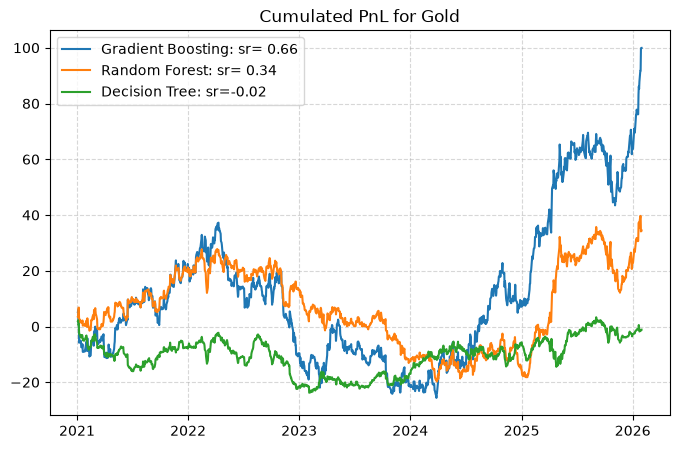

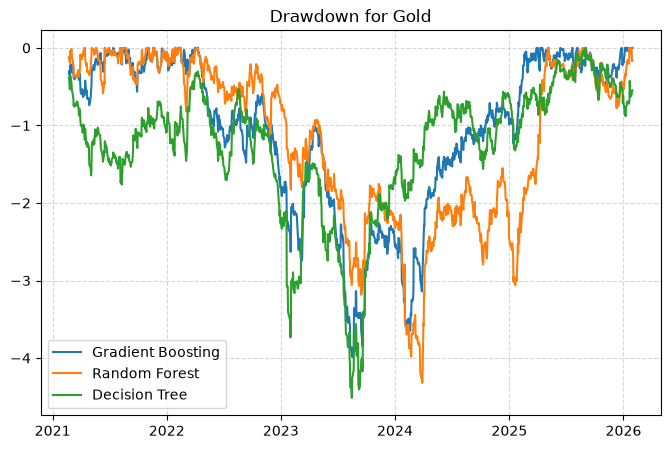

In [28]:
display_results(features=reduced_features_gold_lasso, target=target_gold, best_models=best_models_gold, start_date=PREDICTION_START_DATE, asset="Gold")

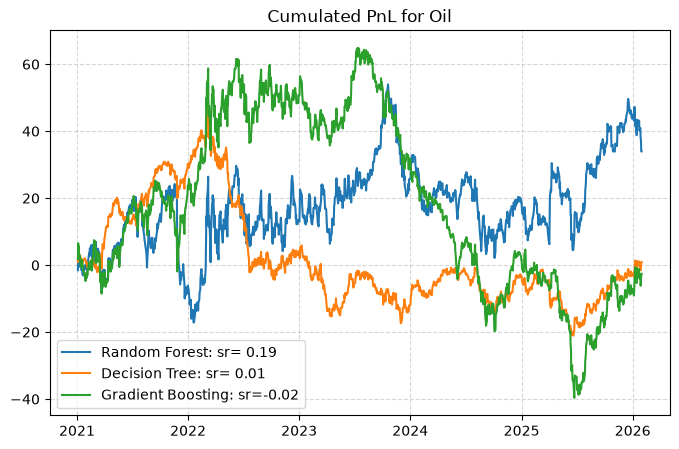

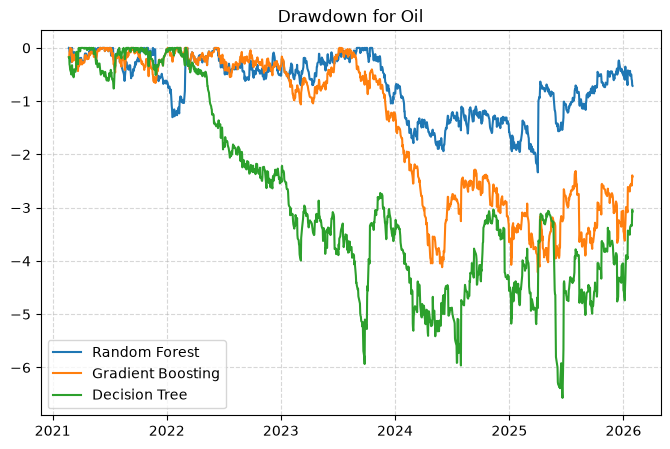

In [29]:
display_results(features=reduced_features_oil_lasso, target=target_oil, best_models=best_models_oil, start_date=PREDICTION_START_DATE)

The conclusion is quite similar here. Profitability is achieved for Gold and Oil using Gradient Boosting. The performance on Oil is very sensitive to the features so we cannot say that the framework is robust for achieving profitability for Oil.

We remark also that when the set of features is reduced, the drawdown of our strategy on Oil is huge compared to the baseline. We can attribute this to the fact that probably our features do not really help predict oil returns. So by keeping all of our information rather than reducing it, we are able to make far better predictions.

### 4.2.3 Sensitivity to the length of the training window

The baseline retrains on the last 120 days. We vary this window for the best gold model to check that the result is not tied to one particular choice.

In [30]:
# NEW cell — sensitivity of the gold Gradient Boosting strategy to the rolling training window
def window_sensitivity(features, target, model, windows=(60, 100, 250), test_size=40,
                       start_date=PREDICTION_START_DATE):
    rows = []
    for w in windows:
        bt = Backtester(estimator=clone(model), max_train_size=w, test_size=test_size,
                        pred_lag=1, start_date=start_date)
        bt.compute_holdings(features, target)
        bt.compute_pnl(target)
        pnl = bt.pnl_.dropna()
        rows.append({"train window (days)": w,
                     "Sharpe": sharpe_ratio(pnl, num_period_per_year=252),
                     "Cumulated PnL": pnl.sum()})
    return pd.DataFrame(rows).set_index("train window (days)").round(2)

window_sensitivity(features_gold, target_gold, best_models_gold["Gradient Boosting"])

,Sharpe,Cumulated PnL
train window (days),,
60,1.08,126.75
100,1.47,206.31
250,0.46,73.84


We can see that the training window has an impact on our cumulated PnL and our Sharpe. This suggests that training our models on all the past data can introduce a lot of noise and degrade the performance.

### 4.2.4 Summary of the robustness results
- For **gold**, Gradient Boosting is the best model under all three feature sets, and its Sharpe ratio stays in the range **0.66–1.04**: the main finding is **stable** with respect to feature selection. Reducing the feature set slightly lowers performance rather than improving it, so the full set of lags carries useful information.
- The **Random Forest** is unstable and the **Decision Tree** stays weak, so the conclusion holds for boosting, not for tree-based models in general.
- For **oil**, results change sign depending on the feature set and the model with no consistent winner.
- Being able to tune the window size we use for training is key to achieve profitability since performance (pnl and sharpe) vary with the training window size.

# 5. Conclusion

**Main findings.** Starting from the forecasting exercise of Cohen & Aiche (2023), we show that a gradient-boosting model trained on lagged returns of global equity indices, commodities, the US yield and the VIX produces a **profitable out-of-sample timing strategy for gold** over 2021–2026 (Sharpe ≈ 1.04 in the baseline and 0.66–0.79 after feature selection). Random forests and single trees are less reliable, and the same approach **does not work for oil**.

**Limitations of our work.**
- **Transaction costs and slippage are not modelled**; with daily rebalancing they could substantially reduce the Sharpe ratio.
- Much of the PnL is earned during the **2024–2025 gold rally**; the strategy may partly capture a regime (strong trend) rather than a stable relationship.
- We did a single test period and a single random seed to ensure reproducibility.

# References

1. Cohen, G. & Aiche, A. (2023). Forecasting gold price using machine learning methodologies. *Chaos, Solitons & Fractals*, 175, 114079. https://doi.org/10.1016/j.chaos.2023.114079